In [1]:
import numpy as np
import  pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import os
import torch, torchaudio
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import IPython.display as ipd
import random
import seaborn as sns
from sklearn.model_selection import StratifiedShuffleSplit

# Data Loading Pipeline

In [5]:
BASE = "/kaggle/input/competitions/birdclef-2025"  # <-- CHANGE THIS to what FOUND printed
# example: BASE = "/kaggle/input/birdclef-2025/birdclef-2025" if needed

train = pd.read_csv(f"{BASE}/train.csv")
taxonomy = pd.read_csv(f"{BASE}/taxonomy.csv")
print(BASE, train.shape)

/kaggle/input/competitions/birdclef-2025 (28564, 13)


In [6]:
taxonomy.head()

,primary_label,inat_taxon_id,scientific_name,common_name,class_name
0,1139490,1139490,Ragoniella pulchella,Ragoniella pulchella,Insecta
1,1192948,1192948,Oxyprora surinamensis,Oxyprora surinamensis,Insecta
2,1194042,1194042,Copiphora colombiae,Copiphora colombiae,Insecta
3,126247,126247,Leptodactylus insularum,Spotted Foam-nest Frog,Amphibia
4,1346504,1346504,Neoconocephalus brachypterus,Neoconocephalus brachypterus,Insecta


In [7]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [43]:
sample_df=train.sample(frac=0.3,random_state=42)
sample_df.shape

(8569, 13)

In [44]:
labels=sorted(train['primary_label'].unique())
label2idx={l:i for i,l in enumerate(labels)}
idx2label={i:l for l,i in label2idx.items()}

In [45]:
class CFG:
    SR=32000
    DURATION=5
    N_MELS=128
    BATCH=32

In [46]:
class BirdDataset(Dataset):
    def __init__(self, df):
        self.df = df
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=CFG.SR, n_mels=CFG.N_MELS, f_min=50, f_max=14000, n_fft=1024, hop_length=512
        )
        self.db = torchaudio.transforms.AmplitudeToDB()

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        row=self.df.iloc[idx]
        path = os.path.join(BASE, "train_audio", row['filename'])
        wav,sr=torchaudio.load(path)
        wav=wav.mean(dim=0)
        if sr != CFG.SR:
            resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=CFG.SR)
            wav = resampler(wav)
        target = CFG.SR * CFG.DURATION
        if len(wav) > target:
            start = torch.randint(0, len(wav)-target, (1,)).item()
            wav = wav[start:start+target]
        else:
            wav = F.pad(wav, (0, target - len(wav)))
            
        mel = self.mel(wav)
        mel = self.db(mel)
        mel = (mel - mel.mean()) / (mel.std() + 1e-6)
        
        label = label2idx[row['primary_label']]
        return mel, label


In [47]:
splitter=StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=42)

In [48]:
counts=sample_df['primary_label'].value_counts()
counts

primary_label
grekis     301
compau     256
trokin     206
roahaw     190
banana     179
          ... 
1192948      1
66893        1
868458       1
134933       1
65336        1
Name: count, Length: 195, dtype: int64

In [49]:
rare_classes=counts[counts==1].index
rare_classes.shape

(14,)

In [50]:
sample_df = sample_df[~sample_df['primary_label'].isin(rare_classes)].reset_index(drop=True)

In [51]:
sample_df.shape

(8555, 13)

In [52]:
train_idx, val_idx = next(splitter.split(sample_df, sample_df['primary_label']))

In [53]:
train_df = sample_df.iloc[train_idx].reset_index(drop=True)
val_df = sample_df.iloc[val_idx].reset_index(drop=True)

print(f"Train size: {len(train_df)} | Val size: {len(val_df)}")

Train size: 6844 | Val size: 1711


In [54]:
train_dataset=BirdDataset(train_df)
val_dataset=BirdDataset(val_df)

In [55]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

In [56]:
mels, labs = next(iter(train_loader))
print("Batch shape:", mels.shape)       
print("Labels shape:", labs.shape)

Batch shape: torch.Size([32, 128, 313])
Labels shape: torch.Size([32])


# Buidling Hybird Model

In [57]:
import torch.nn as nn
import timm

class HybridBirdModel(nn.Module):
    def __init__(self, num_classes=206):
        super().__init__()
        
        # Step A: Backbone (CNN feature extractor)
        self.backbone = timm.create_model(
            'tf_efficientnet_b0', 
            pretrained=True, 
            in_chans=1, 
            num_classes=0, 
            global_pool=''
        )
        
        # Step C: Transformer (Processes the sequence of patches)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=1280, 
            nhead=8, 
            dropout=0.1, 
            batch_first=True # Crucial: PyTorch expects [Batch, Seq, Features]
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        
        # Step D: Final Classifier
        self.classifier = nn.Linear(1280, num_classes)

    def forward(self, x):
        # print(f"Input: {x.shape}")
        features = self.backbone(x)
        # print(f"After CNN: {features.shape}")
        
        features = features.permute(0, 2, 3, 1)
        # print(f"After Permute: {features.shape}")
        
        features = features.flatten(1, 2)
        # print(f"After Flatten: {features.shape}")
        
        trans_out = self.transformer(features)
        # print(f"After Transformer: {trans_out.shape}")
        
        pooled = trans_out.mean(dim=1)
        # print(f"After Pooling: {pooled.shape}")
        
        logits = self.classifier(pooled)
        # print(f"After Classifier: {logits.shape}")
        return logits

In [58]:
model = HybridBirdModel(num_classes=206).to(device)
dummy = torch.randn(2, 1, 128, 313).to(device)

with torch.no_grad():
    out = model(dummy)

print(out.shape) # MUST PRINT: torch.Size([2, 206])

torch.Size([2, 206])


# The Training Loop

In [59]:
import time
import torch.optim as optim

# --- 1. INSTANTIATE THE HYBRID MODEL ---
# Make sure HybridBirdModel class is already defined in a previous cell!
model = HybridBirdModel(num_classes=206).to(device)

# --- 2. SETUP OPTIMIZER & SCHEDULER (The "Gentler Touch") ---
criterion = torch.nn.CrossEntropyLoss()

# Notice the lr=5e-4 
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-2)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

try:
    scaler = torch.amp.GradScaler('cuda')
except AttributeError:
    scaler = torch.cuda.amp.GradScaler()

# --- 3. HISTORY DICTIONARY FOR PLOTTING ---
history = {'train_loss': [],'val_loss': []}
epochs = 10

# --- 4. THE TRAINING LOOP ---
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    start_time = time.time()
    
    for batch_idx, (mels, labs) in enumerate(train_loader):
        
        # Move data to GPU and add channel dim
        mels = mels.to(device).unsqueeze(1)
        labs = labs.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass with Mixed Precision
        with torch.cuda.amp.autocast():
            outputs = model(mels)
            loss = criterion(outputs, labs)
            
        # Backward pass with Scaler
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        # Track loss
        running_loss += loss.item()
        
        if (batch_idx + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx+1}/{len(train_loader)}] | Loss: {loss.item():.4f}")
            
    # Step the scheduler ONCE per epoch
    scheduler.step()
    
    # Calculate average loss for the epoch
    avg_train_loss = running_loss / len(train_loader)
    history['train_loss'].append(avg_train_loss) # <--- SAVE FOR PLOTTING
    
    end_time = time.time()
    print(f"=== Epoch {epoch+1} Complete | Avg Train Loss: {avg_train_loss:.4f} | Time: {end_time - start_time:.1f}s ===")
    print("-" * 50)

/tmp/ipykernel_49/1005546130.py:40: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [1/10] | Batch [10/214] | Loss: 5.1718
Epoch [1/10] | Batch [20/214] | Loss: 4.7918
Epoch [1/10] | Batch [30/214] | Loss: 5.1099
Epoch [1/10] | Batch [40/214] | Loss: 4.7702
Epoch [1/10] | Batch [50/214] | Loss: 4.4875
Epoch [1/10] | Batch [60/214] | Loss: 4.3931
Epoch [1/10] | Batch [70/214] | Loss: 4.5784
Epoch [1/10] | Batch [80/214] | Loss: 4.3006
Epoch [1/10] | Batch [90/214] | Loss: 4.3473
Epoch [1/10] | Batch [100/214] | Loss: 4.0786
Epoch [1/10] | Batch [110/214] | Loss: 3.8916
Epoch [1/10] | Batch [120/214] | Loss: 4.0064
Epoch [1/10] | Batch [130/214] | Loss: 4.1786
Epoch [1/10] | Batch [140/214] | Loss: 4.3314
Epoch [1/10] | Batch [150/214] | Loss: 4.2518
Epoch [1/10] | Batch [160/214] | Loss: 3.5468
Epoch [1/10] | Batch [170/214] | Loss: 3.9796
Epoch [1/10] | Batch [180/214] | Loss: 3.9005
Epoch [1/10] | Batch [190/214] | Loss: 3.8348
Epoch [1/10] | Batch [200/214] | Loss: 3.8270
Epoch [1/10] | Batch [210/214] | Loss: 3.5816
=== Epoch 1 Complete | Avg Train Loss: 4.26

# evaluation

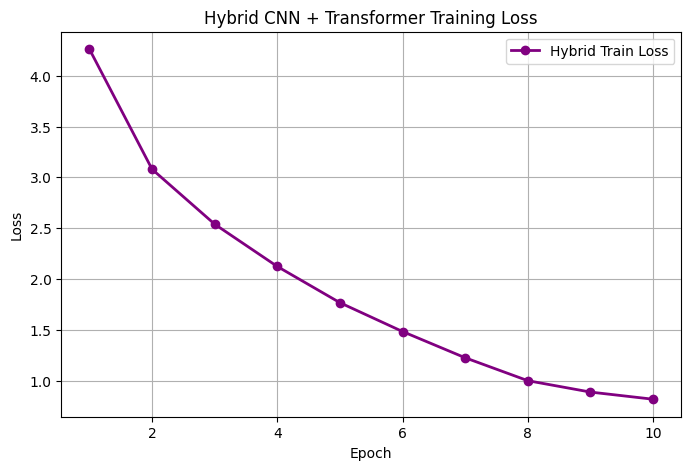

✅ Model saved as 'hybrid_efficientnet_transformer2.pth'

Running validation...


/tmp/ipykernel_49/3749022966.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


🏆 Hybrid Validation Accuracy: 55.35%
Correct predictions: 947 / 1711


In [60]:
import matplotlib.pyplot as plt

# 1. Plot the Hybrid Training Loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), history['train_loss'], marker='o', color='purple', linewidth=2, label='Hybrid Train Loss')
plt.title('Hybrid CNN + Transformer Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

# 2. Save the model weights
torch.save(model.state_dict(), 'hybrid_efficientnet_transformer2.pth')
print("✅ Model saved as 'hybrid_efficientnet_transformer2.pth'\n")

# 3. Run Validation to check accuracy
model.eval()
correct = 0
total = 0

print("Running validation...")
with torch.no_grad():
    for mels, labs in val_loader:
        mels = mels.to(device).unsqueeze(1) # [B, 1, 128, 313]
        labs = labs.to(device)
        
        with torch.cuda.amp.autocast():
            outputs = model(mels)
            
        preds = outputs.argmax(dim=1)
        correct += (preds == labs).sum().item()
        total += labs.size(0)

val_acc = correct / total
print(f"🏆 Hybrid Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Correct predictions: {correct} / {total}")